In [45]:
import pandas as pd

df1 = pd.read_excel(r"C:\Users\Vanshika Koruprolu\OneDrive\Desktop\EV-Battery-Health-prediction\data\raw\EV Lithium Ion Battery State of Health Dataset\EV Lithium Ion Battery State of Health Dataset\Discharge AH.xlsx")
df2 = pd.read_excel(r"C:\Users\Vanshika Koruprolu\OneDrive\Desktop\EV-Battery-Health-prediction\data\raw\EV Lithium Ion Battery State of Health Dataset\EV Lithium Ion Battery State of Health Dataset\Discharge Summary.xlsx")
df3 = pd.read_excel(r"C:\Users\Vanshika Koruprolu\OneDrive\Desktop\EV-Battery-Health-prediction\data\raw\EV Lithium Ion Battery State of Health Dataset\EV Lithium Ion Battery State of Health Dataset\SoH Data.xlsx")

print(df1.shape, df2.shape, df3.shape)

(50285, 9) (168, 2) (168, 4)


In [46]:
print("Discharge AH columns:")
print(df1.columns.tolist())

print("Discharge Summary columns:")
print(df2.columns.tolist())

print("SoH Data columns:")
print(df3.columns.tolist())

Discharge AH columns:
['Cycle_Number', 'Cycle_Type', 'Ambient_Temperature', 'Time', 'Current_measured', 'Voltage_measured', 'Current Mod', 'delta t', 'Discharge Ah']
Discharge Summary columns:
['Dis-ch Cycle', 'Dis-chg Ah']
SoH Data columns:
['Charge Cycle', 'Cycle #', 'Dis-chg Ah', 'SoH']


In [47]:
print("Missing values in df1:")
print(df1.isnull().sum())

print("Missing values in df2:")
print(df2.isnull().sum())

print("Missing values in df3:")
print(df3.isnull().sum())

Missing values in df1:
Cycle_Number           0
Cycle_Type             0
Ambient_Temperature    0
Time                   0
Current_measured       0
Voltage_measured       0
Current Mod            0
delta t                0
Discharge Ah           1
dtype: int64
Missing values in df2:
Dis-ch Cycle    0
Dis-chg Ah      0
dtype: int64
Missing values in df3:
Charge Cycle    0
Cycle #         0
Dis-chg Ah      0
SoH             0
dtype: int64


In [48]:
print(df1[df1["Discharge Ah"].isnull()])

      Cycle_Number Cycle_Type  Ambient_Temperature  Time  Current_measured  \
7827           110  discharge                   24   0.0         -0.000853   

      Voltage_measured  Current Mod   delta t  Discharge Ah  
7827          4.186405     0.000853 -3368.266           NaN  


In [49]:
print(df1.columns.tolist())

['Cycle_Number', 'Cycle_Type', 'Ambient_Temperature', 'Time', 'Current_measured', 'Voltage_measured', 'Current Mod', 'delta t', 'Discharge Ah']


In [50]:
cycle_features = df1.groupby("Cycle_Number").agg(
    Measurement_Count=("Cycle_Number", "size"),
    Ambient_Temperature=("Ambient_Temperature", "mean"),
    Average_Voltage=("Voltage_measured", "mean"),
    Minimum_Voltage=("Voltage_measured", "min"),
    Maximum_Voltage=("Voltage_measured", "max"),
    Average_Current=("Current_measured", "mean"),
    Minimum_Current=("Current_measured", "min"),
    Maximum_Current=("Current_measured", "max"),
    Maximum_Time=("Time", "max"),
    Discharge_Capacity_Ah=("Discharge Ah", "sum")
).reset_index()

In [51]:
print(cycle_features.shape)
print(cycle_features.columns.tolist())

(168, 11)
['Cycle_Number', 'Measurement_Count', 'Ambient_Temperature', 'Average_Voltage', 'Minimum_Voltage', 'Maximum_Voltage', 'Average_Current', 'Minimum_Current', 'Maximum_Current', 'Maximum_Time', 'Discharge_Capacity_Ah']


In [52]:
#merging datasets
df = cycle_features.merge(
    df2,
    left_on="Cycle_Number",
    right_on="Dis-ch Cycle",
    how="inner"
)

df = df.merge(
    df3,
    left_on="Cycle_Number",
    right_on="Charge Cycle",
    how="inner"
)





In [53]:
print(df.shape)
print(df.columns.tolist())

(168, 17)
['Cycle_Number', 'Measurement_Count', 'Ambient_Temperature', 'Average_Voltage', 'Minimum_Voltage', 'Maximum_Voltage', 'Average_Current', 'Minimum_Current', 'Maximum_Current', 'Maximum_Time', 'Discharge_Capacity_Ah', 'Dis-ch Cycle', 'Dis-chg Ah_x', 'Charge Cycle', 'Cycle #', 'Dis-chg Ah_y', 'SoH']


In [ ]:
df.to_excel(r"C:\Users\Vanshika Koruprolu\OneDrive\Desktop\EV-Battery-Health-prediction\data\processed\EV_Battery_Merged_Dataset.xlsx", index=False)
df.to_csv(r"C:\Users\Vanshika Koruprolu\OneDrive\Desktop\EV-Battery-Health-prediction\data\processed\EV_Battery_Merged_Dataset.csv", index=False)

In [55]:
#data cleaning
print(df.isnull().sum())



Cycle_Number             0
Measurement_Count        0
Ambient_Temperature      0
Average_Voltage          0
Minimum_Voltage          0
Maximum_Voltage          0
Average_Current          0
Minimum_Current          0
Maximum_Current          0
Maximum_Time             0
Discharge_Capacity_Ah    0
Dis-ch Cycle             0
Dis-chg Ah_x             0
Charge Cycle             0
Cycle #                  0
Dis-chg Ah_y             0
SoH                      0
dtype: int64


In [56]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Cycle_Number           168 non-null    int64  
 1   Measurement_Count      168 non-null    int64  
 2   Ambient_Temperature    168 non-null    float64
 3   Average_Voltage        168 non-null    float64
 4   Minimum_Voltage        168 non-null    float64
 5   Maximum_Voltage        168 non-null    float64
 6   Average_Current        168 non-null    float64
 7   Minimum_Current        168 non-null    float64
 8   Maximum_Current        168 non-null    float64
 9   Maximum_Time           168 non-null    float64
 10  Discharge_Capacity_Ah  168 non-null    float64
 11  Dis-ch Cycle           168 non-null    int64  
 12  Dis-chg Ah_x           168 non-null    float64
 13  Charge Cycle           168 non-null    int64  
 14  Cycle #                168 non-null    int64  
 15  Dis-ch

In [58]:
#checking soh values(target column)
print(df["SoH"].describe())

count    168.000000
mean      75.998118
std       12.214609
min       57.120975
25%       66.316835
50%       73.037351
75%       86.629968
max      100.000000
Name: SoH, dtype: float64


In [59]:
print(df.columns.tolist())

['Cycle_Number', 'Measurement_Count', 'Ambient_Temperature', 'Average_Voltage', 'Minimum_Voltage', 'Maximum_Voltage', 'Average_Current', 'Minimum_Current', 'Maximum_Current', 'Maximum_Time', 'Discharge_Capacity_Ah', 'Dis-ch Cycle', 'Dis-chg Ah_x', 'Charge Cycle', 'Cycle #', 'Dis-chg Ah_y', 'SoH']


In [60]:
df = df.drop(columns=[
    "Dis-ch Cycle",
    "Dis-chg Ah_x",
    "Charge Cycle",
    "Dis-chg Ah_y"
])

df = df.rename(columns={
    "Cycle_Number": "Cycle"
})

In [61]:
print(df.shape)
print(df.columns.tolist())

(168, 13)
['Cycle', 'Measurement_Count', 'Ambient_Temperature', 'Average_Voltage', 'Minimum_Voltage', 'Maximum_Voltage', 'Average_Current', 'Minimum_Current', 'Maximum_Current', 'Maximum_Time', 'Discharge_Capacity_Ah', 'Cycle #', 'SoH']


In [62]:
print(df[["Cycle", "Discharge_Capacity_Ah", "SoH"]].head(10))

   Cycle  Discharge_Capacity_Ah         SoH
0      2               2.051978  100.000000
1      4               2.038456   99.341209
2      6               2.028602   98.860978
3      8               2.016546   98.273463
4     10               2.016070   98.250243
5     12               2.026221   98.744950
6     14               2.024274   98.650099
7     16               1.983444   96.660304
8     18               1.972465   96.125243
9     20               1.967825   95.899106


In [63]:
initial_capacity = df["Discharge_Capacity_Ah"].iloc[0]

df["Calculated_SoH"] = (
    df["Discharge_Capacity_Ah"] / initial_capacity
) * 100

print(df[["Discharge_Capacity_Ah", "SoH", "Calculated_SoH"]].head(10))


   Discharge_Capacity_Ah         SoH  Calculated_SoH
0               2.051978  100.000000      100.000000
1               2.038456   99.341209       99.341013
2               2.028602   98.860978       98.860783
3               2.016546   98.273463       98.273269
4               2.016070   98.250243       98.250049
5               2.026221   98.744950       98.744755
6               2.024274   98.650099       98.649905
7               1.983444   96.660304       96.660113
8               1.972465   96.125243       96.125053
9               1.967825   95.899106       95.898917


In [64]:
#feature selection
X = df.drop(columns=[
    "SoH",
    "Discharge_Capacity_Ah",
    "Calculated_SoH"
])

y = df["SoH"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print(X.head())


Input shape: (168, 11)
Target shape: (168,)
   Cycle  Measurement_Count  Ambient_Temperature  Average_Voltage  \
0      2                197                 24.0         3.556946   
1      4                196                 24.0         3.561476   
2      6                195                 24.0         3.566752   
3      8                194                 24.0         3.568795   
4     10                194                 24.0         3.563971   

   Minimum_Voltage  Maximum_Voltage  Average_Current  Minimum_Current  \
0         2.475768         4.179823        -1.990538        -2.015538   
1         2.351526         4.177288        -1.990278        -2.014902   
2         2.440480         4.178121        -1.989947        -2.014434   
3         2.479156         4.178562        -1.989601        -2.014205   
4         2.280188         4.178250        -1.989548        -2.013996   

   Maximum_Current  Maximum_Time  Cycle #  
0        -0.000434      3690.234        1  
1        -0.00

In [65]:
print(df[["Cycle", "Cycle #"]].head(15))

print("Are both columns equal?",
      (df["Cycle"] == df["Cycle #"]).all())

    Cycle  Cycle #
0       2        1
1       4        2
2       6        3
3       8        4
4      10        5
5      12        6
6      14        7
7      16        8
8      18        9
9      20       10
10     22       11
11     25       12
12     27       13
13     29       14
14     31       15
Are both columns equal? False


In [66]:
X = df.drop(columns=[
    "SoH",
    "Discharge_Capacity_Ah",
    "Calculated_SoH",
    "Cycle #",
    "Ambient_Temperature"
])

y = df["SoH"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print(X.columns.tolist())

Input shape: (168, 9)
Target shape: (168,)
['Cycle', 'Measurement_Count', 'Average_Voltage', 'Minimum_Voltage', 'Maximum_Voltage', 'Average_Current', 'Minimum_Current', 'Maximum_Current', 'Maximum_Time']


In [67]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    shuffle=False
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (134, 9)
Testing data: (34, 9)
Training target: (134,)
Testing target: (34,)


In [68]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [69]:
y_pred = model.predict(X_test)

print("Actual SoH:")
print(y_test.head(10).values)

print("\nPredicted SoH:")
print(y_pred[:10])

Actual SoH:
[65.15307953 64.74506619 64.19133475 64.18327808 64.00304436 63.73646393
 63.16760293 62.85893633 62.9833868  62.64034481]

Predicted SoH:
[65.32993925 64.75028718 64.21662197 64.2366805  64.08567086 63.70867471
 63.17233093 62.96075953 63.00623033 62.77939855]


In [70]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 0.20444928813688681
MSE: 0.06321532895381239
RMSE: 0.2514265876032453
R2 Score: 0.9881683630422825


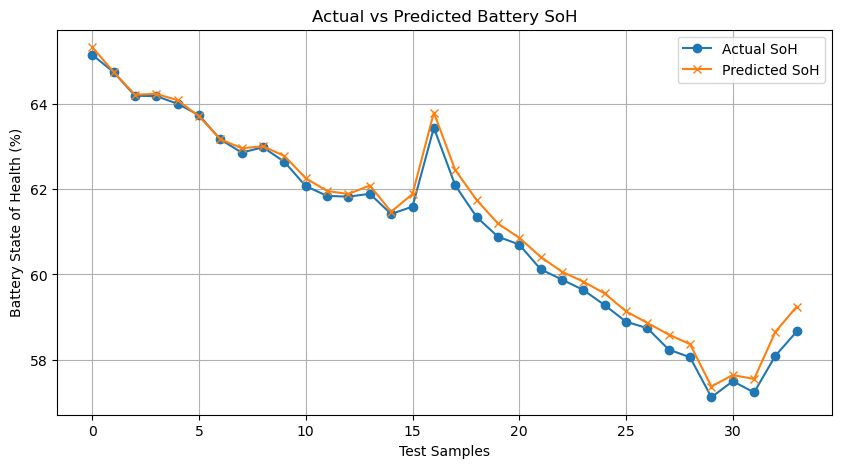

In [71]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(y_test.values, label="Actual SoH", marker="o")
plt.plot(y_pred, label="Predicted SoH", marker="x")

plt.xlabel("Test Samples")
plt.ylabel("Battery State of Health (%)")
plt.title("Actual vs Predicted Battery SoH")

plt.legend()
plt.grid(True)
plt.show()

In [72]:
#Random Forest Regression
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest model training completed!")


Random Forest model training completed!


In [73]:
rf_pred = rf_model.predict(X_test)

print("Actual SoH:")
print(y_test.head(10).values)

print("\nRandom Forest Predicted SoH:")
print(rf_pred[:10])

Actual SoH:
[65.15307953 64.74506619 64.19133475 64.18327808 64.00304436 63.73646393
 63.16760293 62.85893633 62.9833868  62.64034481]

Random Forest Predicted SoH:
[65.84360759 65.14912235 65.13251408 65.11319006 65.1067086  65.161477
 65.0875547  65.02251128 65.07894121 65.05104476]


In [74]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest MAE:", rf_mae)
print("Random Forest MSE:", rf_mse)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R2 Score:", rf_r2)

Random Forest MAE: 4.073978065886713
Random Forest MSE: 22.044548144632184
Random Forest RMSE: 4.69516220642399
Random Forest R2 Score: -3.1259469002333216


In [75]:
print("Training SoH range:")
print(y_train.min(), y_train.max())

print("\nTesting SoH range:")
print(y_test.min(), y_test.max())

Training SoH range:
64.79781951196406 100.0

Testing SoH range:
57.12097547137728 65.15307952889934


In [76]:
#Ridge Regression
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train, y_train)

print("Ridge Regression model training completed!")

Ridge Regression model training completed!


In [77]:
ridge_pred = ridge_model.predict(X_test)

print("Actual SoH:")
print(y_test.head(10).values)

print("\nRidge Regression Predicted SoH:")
print(ridge_pred[:10])

Actual SoH:
[65.15307953 64.74506619 64.19133475 64.18327808 64.00304436 63.73646393
 63.16760293 62.85893633 62.9833868  62.64034481]

Ridge Regression Predicted SoH:
[64.32846049 63.96268395 63.47821463 63.54392615 63.43731791 63.08499784
 62.59559    62.50764307 62.49782265 62.1301098 ]


In [78]:
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_mse = mean_squared_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, ridge_pred)

print("Ridge Regression MAE:", ridge_mae)
print("Ridge Regression MSE:", ridge_mse)
print("Ridge Regression RMSE:", ridge_rmse)
print("Ridge Regression R2 Score:", ridge_r2)

Ridge Regression MAE: 0.6440649661033155
Ridge Regression MSE: 0.5653285631811221
Ridge Regression RMSE: 0.7518833441306717
Ridge Regression R2 Score: 0.8941908168147927
